In [ ]:
import pandas as pd, numpy as np

X = pd.read_csv("/content/secom.data", sep=r"\s+", header=None)

# Read secom_labels.data. Pandas reads it as 2 columns due to the double quotes around the datetime
lab = pd.read_csv("/content/secom_labels.data", sep=r"\s+", header=None,
                  names=["label", "timestamp_raw"])

# Convert the raw timestamp text into real datetimes
lab["timestamp"] = pd.to_datetime(lab["timestamp_raw"], format="%d/%m/%Y %H:%M:%S")

# Give the features readable names (f0 ... f589)
X.columns = [f"f{i}" for i in X.columns]

# Check 1: do the two files line up row for row?
print("X:", X.shape, "| labels:", lab.shape)
assert len(X) == len(lab)

# Check 2: how rare are failures? (-1 = pass, 1 = fail)
print(lab["label"].value_counts())
print("failure rate:", (lab["label"] == 1).mean().round(4))

# Check 3: what period does the data cover?
print(lab["timestamp"].min(), "->", lab["timestamp"].max())

# Check 4: a first look at the numbers
display(X.iloc[:3, :6])

X: (1567, 590) | labels: (1567, 3)
label
-1    1463
 1     104
Name: count, dtype: int64
failure rate: 0.0664
2008-07-19 11:55:00 -> 2008-10-17 06:07:00


,f0,f1,f2,f3,f4,f5
0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0
1,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0
2,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0


features with any missing: 538 of 590
features with >50% missing: 28
rows with at least one NaN: 1.0
f292    0.911934
f293    0.911934
f158    0.911934
f157    0.911934
f492    0.855775
f85     0.855775
f358    0.855775
f220    0.855775
f244    0.649649
f517    0.649649
f109    0.649649
f246    0.649649
f383    0.649649
f382    0.649649
f384    0.649649
f245    0.649649
f111    0.649649
f110    0.649649
f516    0.649649
f518    0.649649
dtype: float64


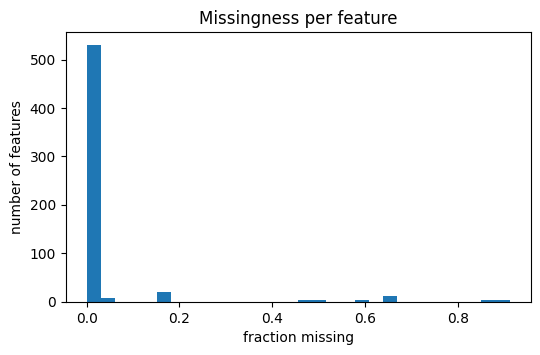

In [ ]:
import matplotlib.pyplot as plt

# Define y as 0/1 where 1 = failure
y = (lab["label"] == 1).astype(int)
ts = lab["timestamp"]

# --- 1. Missing values ---
miss = X.isna().mean().sort_values(ascending=False)
print("features with any missing:", (miss > 0).sum(), "of", X.shape[1])
print("features with >50% missing:", (miss > 0.5).sum())
print("rows with at least one NaN:", X.isna().any(axis=1).mean().round(3))
print(miss.head(20))

plt.figure(figsize=(6,3.5))
plt.hist(miss.values, bins=30)
plt.xlabel("fraction missing"); plt.ylabel("number of features")
plt.title("Missingness per feature"); plt.show()

In [ ]:
# --- 2. Constant features ---
n_const = (X.nunique(dropna=True) <= 1).sum()
print("constant features:", n_const)

# --- 4a. Is the data already in time order? ---
print("sorted by time already?", ts.is_monotonic_increasing)

constant features: 116
sorted by time already? True


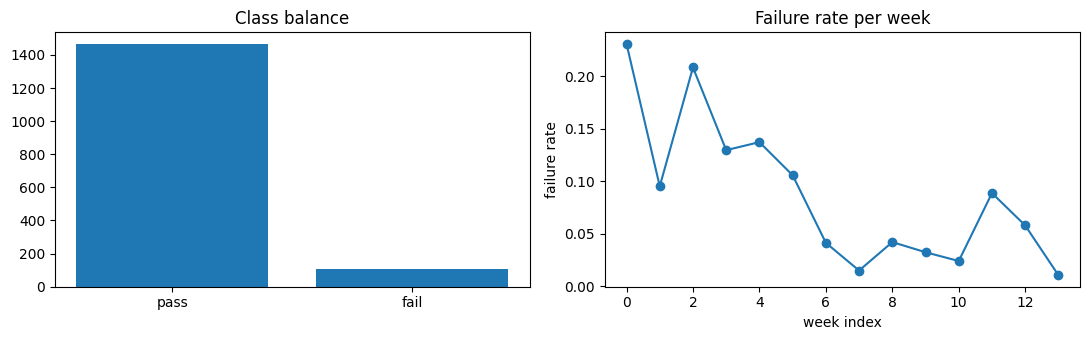

count     14.000000
mean     111.928571
std       60.788997
min       13.000000
25%       61.750000
50%      120.500000
75%      163.000000
max      208.000000
Name: size, dtype: float64


In [ ]:
# --- 3 and 4b. Class balance, and failure rate over time ---
weekly = pd.DataFrame({"week": ts.dt.to_period("W").astype(str), "fail": y}).groupby("week")["fail"].agg(["mean","size"])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].bar(["pass", "fail"], [(y==0).sum(), (y==1).sum()]); ax[0].set_title("Class balance")
ax[1].plot(range(len(weekly)), weekly["mean"].values, marker="o")
ax[1].set_xlabel("week index"); ax[1].set_ylabel("failure rate"); ax[1].set_title("Failure rate per week")
plt.tight_layout(); plt.show()
print(weekly["size"].describe())

In [ ]:
n = len(X)
i_tr, i_va = int(0.6 * n), int(0.8 * n)
splits = {"train": slice(0, i_tr), "val": slice(i_tr, i_va), "test": slice(i_va, n)}

for name, s in splits.items():
    yy, tt = y.iloc[s], ts.iloc[s]
    print(f"{name:5s} n={len(yy):4d}  failures={yy.sum():3d}  rate={yy.mean():.3f}  {tt.min().date()} -> {tt.max().date()}")

train n= 940  failures= 76  rate=0.081  2008-07-19 -> 2008-09-20
val   n= 313  failures= 11  rate=0.035  2008-09-20 -> 2008-10-02
test  n= 314  failures= 17  rate=0.054  2008-10-02 -> 2008-10-17


In [ ]:
from sklearn.model_selection import TimeSeriesSplit

# Development set = first 80% (train + val); test set = last 20%, locked
X_dev, y_dev = X.iloc[:i_va], y.iloc[:i_va]
X_te,  y_te  = X.iloc[i_va:], y.iloc[i_va:]   # do not touch until the final evaluation

tscv = TimeSeriesSplit(n_splits=5)
for k, (tr, va) in enumerate(tscv.split(X_dev), start=1):
    print(f"fold {k}: train n={len(tr):4d} fails={y_dev.iloc[tr].sum():3d} | "
          f"val n={len(va):3d} fails={y_dev.iloc[va].sum():3d}")


fold 1: train n= 213 fails= 29 | val n=208 fails= 26
fold 2: train n= 421 fails= 55 | val n=208 fails= 10
fold 3: train n= 629 fails= 65 | val n=208 fails=  6
fold 4: train n= 837 fails= 71 | val n=208 fails=  6
fold 5: train n=1045 fails= 77 | val n=208 fails= 10


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import average_precision_score
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn.impute")

def make_pipe(clf):
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),   # fill NaN with the training median
        ("var",    VarianceThreshold(0.0)),             # drop features constant in the training block
        ("scale",  StandardScaler()),                   # zero mean, unit variance (training stats)
        ("clf",    clf),
    ])

def cv_scores(model, X_dev, y_dev, tscv):
    rows = []
    for k, (tr, va) in enumerate(tscv.split(X_dev), start=1):
        model.fit(X_dev.iloc[tr], y_dev.iloc[tr])
        s = model.predict_proba(X_dev.iloc[va])[:, 1]
        rows.append({"fold": k,
                     "val_fails": int(y_dev.iloc[va].sum()),
                     "no_skill": y_dev.iloc[va].mean(),
                     "PR-AUC": average_precision_score(y_dev.iloc[va], s)})
    return pd.DataFrame(rows)

dummy = make_pipe(DummyClassifier(strategy="prior"))
logreg = make_pipe(LogisticRegression(C=0.01, class_weight="balanced", max_iter=2000))

res_dummy = cv_scores(dummy, X_dev, y_dev, tscv)
res_lr    = cv_scores(logreg, X_dev, y_dev, tscv)

print("DUMMY");               print(res_dummy.round(3))
print("\nLOGISTIC REGRESSION"); print(res_lr.round(3))
print("\nmean PR-AUC  dummy: %.3f   logreg: %.3f" % (res_dummy["PR-AUC"].mean(), res_lr["PR-AUC"].mean()))

DUMMY
   fold  val_fails  no_skill  PR-AUC
0     1         26     0.125   0.125
1     2         10     0.048   0.048
2     3          6     0.029   0.029
3     4          6     0.029   0.029
4     5         10     0.048   0.048

LOGISTIC REGRESSION
   fold  val_fails  no_skill  PR-AUC
0     1         26     0.125   0.114
1     2         10     0.048   0.129
2     3          6     0.029   0.038
3     4          6     0.029   0.056
4     5         10     0.048   0.042

mean PR-AUC  dummy: 0.056   logreg: 0.076


In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif

def make_pipe_k(clf, k):
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("var",    VarianceThreshold(0.0)),
        ("scale",  StandardScaler()),
        ("select", SelectKBest(f_classif, k=k)),   # chosen from the training block only
        ("clf",    clf),
    ])

out = []
for k in [10, 30, 100]:
    m = make_pipe_k(LogisticRegression(C=0.1, class_weight="balanced", max_iter=2000), k)
    r = cv_scores(m, X_dev, y_dev, tscv)
    r["gain"] = r["PR-AUC"] - r["no_skill"]
    out.append({"k": k, **{f"fold{f}": g for f, g in zip(r["fold"], r["gain"].round(3))},
                "mean gain": r["gain"].mean().round(3)})
pd.DataFrame(out)

,k,fold1,fold2,fold3,fold4,fold5,mean gain
0,10,0.004,0.065,0.117,0.012,0.018,0.043
1,30,0.007,0.075,0.172,-0.005,0.047,0.059
2,100,-0.010,0.167,0.176,0.016,0.029,0.075


In [ ]:
from sklearn.ensemble import RandomForestClassifier

def gain_row(name, model):
    r = cv_scores(model, X_dev, y_dev, tscv)
    g = r["PR-AUC"] - r["no_skill"]
    return {"model": name, **{f"fold{f}": v for f, v in zip(r["fold"], g.round(3))},
            "mean gain": round(g.mean(), 3)}

lr = make_pipe_k(LogisticRegression(C=0.1, class_weight="balanced", max_iter=2000), k=100)
rf = make_pipe_k(RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                        class_weight="balanced_subsample",
                                        n_jobs=-1, random_state=42), k=100)

pd.DataFrame([gain_row("logreg k=100", lr), gain_row("random forest k=100", rf)])

,model,fold1,fold2,fold3,fold4,fold5,mean gain
0,logreg k=100,-0.01,0.167,0.176,0.016,0.029,0.075
1,random forest k=100,0.04,0.102,0.010,0.321,0.002,0.095


In [ ]:
tr, va = list(tscv.split(X_dev))[3]            # fold 4 (index 3)
fail_idx = y_dev.iloc[va][y_dev.iloc[va] == 1].index

for name, m in [("logreg", lr), ("forest", rf)]:
    m.fit(X_dev.iloc[tr], y_dev.iloc[tr])
    s = pd.Series(m.predict_proba(X_dev.iloc[va])[:, 1], index=X_dev.index[va])
    ranks = s.rank(ascending=False, method="first")
    print(name, "ranks of the failures among", len(va), "units:", sorted(ranks[fail_idx].astype(int)))

print("failure timestamps:", ts.loc[fail_idx].dt.strftime("%m-%d %H:%M").tolist())

logreg ranks of the failures among 208 units: [12, 64, 101, 104, 115, 144]
forest ranks of the failures among 208 units: [2, 3, 7, 10, 85, 126]
failure timestamps: ['09-17 04:23', '09-19 16:58', '09-19 20:19', '09-19 21:09', '09-19 21:59', '09-23 11:14']


In [ ]:
for name, m in [("logreg", lr), ("forest", rf)]:
    m.fit(X_dev.iloc[tr], y_dev.iloc[tr])
    s = pd.Series(m.predict_proba(X_dev.iloc[va])[:, 1], index=X_dev.index[va])
    ranks = s.rank(ascending=False, method="first").astype(int)
    print(name)
    print(pd.DataFrame({"time": ts.loc[fail_idx].dt.strftime("%m-%d %H:%M"), "rank": ranks[fail_idx]}))

logreg
             time  rank
871   09-17 04:23   104
914   09-19 16:58   101
924   09-19 20:19    12
926   09-19 21:09    64
929   09-19 21:59   144
1029  09-23 11:14   115
forest
             time  rank
871   09-17 04:23     2
914   09-19 16:58     3
924   09-19 20:19    10
926   09-19 21:09     7
929   09-19 21:59    85
1029  09-23 11:14   126


#Fixed decisions (made using development data only, before any test-set evaluation)

Primary model: logistic regression, class_weight="balanced", C = 0.01, k = 10 features. Chosen by the rule “simplest setting whose mean cross-validated gain over baseline is within 0.01 of the best.” All three tested values of k qualified (mean gain 0.053 to 0.058), so we took the fewest features.

Secondary model: random forest, k = 100, 300 trees, min_samples_leaf=3. Reported for comparison only. It won 2 of 5 folds, and its higher mean depended on one fold, so it does not replace the simpler model.

Training data for final fit: all development rows (the first 80% by time, 87 failures).

Metrics: PR-AUC and gain over the test no-skill rate (the primary metric), recall at precision ≥ 0.15, and recall within the top 10% of flagged units.

Uncertainty: bootstrap resampling of whole calendar days, because failures cluster in bursts.

The test set is evaluated once. No model or setting changes after seeing its results.

In [ ]:
from sklearn.metrics import precision_recall_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

final_lr = make_pipe_k(LogisticRegression(C=0.01, class_weight="balanced", max_iter=2000), k=10)
final_rf = make_pipe_k(RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                       class_weight="balanced_subsample", n_jobs=-1, random_state=42), k=100)

scores = {}
for name, m in [("logreg", final_lr), ("forest", final_rf)]:
    m.fit(X_dev, y_dev)                       # fit on all development data
    scores[name] = m.predict_proba(X_te)[:, 1]

def recall_at_precision(yt, s, min_p):
    p, r, _ = precision_recall_curve(yt, s)
    ok = p[:-1] >= min_p
    return r[:-1][ok].max() if ok.any() else 0.0

def recall_in_top_frac(yt, s, frac=0.10):
    k = int(np.ceil(frac * len(s)))
    return yt[np.argsort(-s)[:k]].sum() / yt.sum()

yt = y_te.values
print(f"test: n={len(yt)}, failures={yt.sum()}, no-skill PR-AUC={yt.mean():.3f}")
for name, s in scores.items():
    print(f"{name:7s} PR-AUC={average_precision_score(yt, s):.3f} | "
          f"recall@precision>=0.15={recall_at_precision(yt, s, 0.15):.2f} | "
          f"recall in top 10%={recall_in_top_frac(yt, s):.2f}")

# --- bootstrap over calendar days (keeps failure bursts together) ---
days = ts.iloc[i_va:].dt.date.values
day_list = np.unique(days)
idx_by_day = {d: np.where(days == d)[0] for d in day_list}
rng = np.random.default_rng(42)
gains = {k: [] for k in scores}; diffs = []
for _ in range(2000):
    pick = rng.choice(day_list, size=len(day_list), replace=True)
    ii = np.concatenate([idx_by_day[d] for d in pick])
    if yt[ii].sum() == 0: continue
    base = yt[ii].mean(); g = {}
    for k, s in scores.items():
        g[k] = average_precision_score(yt[ii], s[ii]) - base; gains[k].append(g[k])
    diffs.append(g["forest"] - g["logreg"])

ci = lambda a: np.percentile(a, [2.5, 97.5]).round(3)
print(f"\nbootstrap over {len(day_list)} test days ({len(diffs)} valid resamples)")
for k in gains: print(f"{k:7s} gain over baseline: median={np.median(gains[k]):.3f}, 95% CI {ci(gains[k])}")
print(f"forest - logreg difference: median={np.median(diffs):.3f}, 95% CI {ci(diffs)}")

pd.DataFrame({"timestamp": ts.iloc[i_va:].values, "y_true": yt,
              "score_logreg": scores["logreg"], "score_forest": scores["forest"]}
            ).to_csv("test_predictions.csv", index=False)

test: n=314, failures=17, no-skill PR-AUC=0.054
logreg  PR-AUC=0.227 | recall@precision>=0.15=0.53 | recall in top 10%=0.35
forest  PR-AUC=0.107 | recall@precision>=0.15=0.00 | recall in top 10%=0.18

bootstrap over 16 test days (1999 valid resamples)
logreg  gain over baseline: median=0.195, 95% CI [0.017 0.45 ]
forest  gain over baseline: median=0.061, 95% CI [0.018 0.121]
forest - logreg difference: median=-0.134, 95% CI [-0.376  0.031]


In [ ]:
te = pd.DataFrame({"time": ts.iloc[i_va:].values, "y": yt,
                   "lr": scores["logreg"], "rf": scores["forest"]}, index=X_te.index)
te["rank_lr"] = te["lr"].rank(ascending=False, method="first").astype(int)
te["rank_rf"] = te["rf"].rank(ascending=False, method="first").astype(int)

fails = te[te.y == 1].sort_values("time")
print(fails[["time", "rank_lr", "rank_rf"]].to_string())

top = te.nsmallest(32, "rank_lr")
print("\nlogreg top-32 flagged: failures =", top.y.sum(), "of", len(top))
by_day = te.groupby(te.time.dt.date).agg(units=("y", "size"), failures=("y", "sum"))
by_day["flagged_by_lr_top32"] = top.groupby(top.time.dt.date).size().reindex(by_day.index).fillna(0).astype(int)
print(by_day.to_string())

                    time  rank_lr  rank_rf
1254 2008-10-02 21:32:00       36      128
1302 2008-10-04 23:18:00      252      159
1303 2008-10-05 00:33:00       44       59
1324 2008-10-05 15:30:00       75       48
1325 2008-10-05 15:35:00       24       61
1327 2008-10-05 16:37:00        4       87
1328 2008-10-05 16:49:00        7       65
1329 2008-10-05 18:46:00      197       89
1342 2008-10-06 03:50:00      218      243
1343 2008-10-06 03:57:00      135      180
1363 2008-10-06 13:38:00       58       11
1364 2008-10-06 13:55:00       11       40
1365 2008-10-06 15:00:00      146       26
1400 2008-10-07 13:10:00       30       23
1438 2008-10-09 04:34:00      295      168
1443 2008-10-09 15:55:00      180      133
1519 2008-10-15 02:42:00        1       33

logreg top-32 flagged: failures = 6 of 32
            units  failures  flagged_by_lr_top32
time                                            
2008-10-02      7         1                    3
2008-10-03     25         0         

In [ ]:
from collections import Counter

best_pipe = lambda: make_pipe_k(LogisticRegression(C=0.01, class_weight="balanced", max_iter=2000), k=10)

sel = []
for k, (tr, va) in enumerate(tscv.split(X_dev), start=1):
    m = best_pipe().fit(X_dev.iloc[tr], y_dev.iloc[tr])
    sel.append(list(m[:-1].get_feature_names_out()))   # names of the 10 kept sensors

final = best_pipe().fit(X_dev, y_dev)
final_feats = set(final[:-1].get_feature_names_out())

counts = Counter(f for fs in sel for f in fs)
tab = (pd.DataFrame({"times_selected_of_5": pd.Series(counts)})
         .assign(in_final_model=lambda d: d.index.isin(final_feats))
         .sort_values(["times_selected_of_5", "in_final_model"], ascending=False))
print(tab.head(15))
print("\nchosen in all 5 folds:", (tab.times_selected_of_5 == 5).sum(),
      "| in >=3 folds:", (tab.times_selected_of_5 >= 3).sum(),
      "| ever chosen:", len(tab))
print("final-model features:", sorted(final_feats))

      times_selected_of_5  in_final_model
f21                     4            True
f430                    4            True
f434                    4            True
f435                    4            True
f59                     3            True
f431                    3            True
f436                    3            True
f22                     3           False
f103                    1            True
f205                    1           False
f248                    1           False
f333                    1           False
f336                    1           False
f341                    1           False
f345                    1           False

chosen in all 5 folds: 0 | in >=3 folds: 8 | ever chosen: 30
final-model features: ['f103', 'f129', 'f21', 'f430', 'f431', 'f434', 'f435', 'f436', 'f510', 'f59']


In [ ]:
never = [f for f in final_feats if f not in tab.index]
print("in final model but never picked in any fold:", never)

stable = ["f21", "f22", "f430", "f431", "f434", "f435", "f436", "f59"]
print(X_dev[stable].corr().round(2))

in final model but never picked in any fold: ['f510', 'f129']
       f21   f22  f430  f431  f434  f435  f436   f59
f21   1.00 -0.82  0.70  0.63  0.67  0.68  0.68 -0.01
f22  -0.82  1.00 -0.68 -0.51 -0.67 -0.68 -0.68  0.01
f430  0.70 -0.68  1.00  0.91  0.96  0.96  0.96  0.07
f431  0.63 -0.51  0.91  1.00  0.94  0.94  0.94  0.08
f434  0.67 -0.67  0.96  0.94  1.00  1.00  1.00  0.08
f435  0.68 -0.68  0.96  0.94  1.00  1.00  1.00  0.08
f436  0.68 -0.68  0.96  0.94  1.00  1.00  1.00  0.08
f59  -0.01  0.01  0.07  0.08  0.08  0.08  0.08  1.00
